# 🏦 Bank Müştəri İtkisi (Churn) Proqnozlaşdırılması - ML Pipeline

**Məqsəd:** Bankın müştəri davranışlarını (tranzaksiya və kredit tarixçəsi) analiz edərək, gələcəkdə bankı tərk etmə (churn) ehtimalı yüksək olan riskli müştəriləri qabaqcadan müəyyən etmək. 

Bu layihədə klassik *End-to-End* maşın öyrənməsi yanaşmasından istifadə olunacaq:
1. **Feature Engineering:** Tranzaksiya və kredit məlumatlarının müştəri səviyyəsində cəmlənməsi.
2. **Data Preprocessing:** Məlumat sızmasının (Data Leakage) qarşısını alan Scikit-Learn `Pipeline` arxitekturası.
3. **Hyperparameter Tuning:** Random Forest modeli üçün ən optimal parametrlərin axtarışı.
4. **Biznes Həddi (Threshold):** Modelin qərar həddinin biznesin tələblərinə (Recall) uyğun optimallaşdırılması.

---

## Mərhələ 1: Məlumatların Birləşdirilməsi və Əlamət Mühəndisliyi (Feature Engineering)

Bankın databazasında məlumatlar fərqli cədvəllərdə (Müştəri, Tranzaksiya, Kredit) saxlanılır. Modeli öyrətmək üçün bütün bu detallı cədvəlləri tək bir müştəri oxunda (5,000 unikal `customer_id`) birləşdirməliyik. 
Eyni zamanda, xarici valyutada olan (USD, EUR) bütün əməliyyatlar real məzənnə ilə AZN-ə çevrilməlidir.

In [44]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/workspaces/Bank_Analysis/data/bank_data")

Müştəri Profil Datanın Oxunması

In [45]:
customers = pd.read_csv(DATA_DIR / "customers.csv")
customers["customer_id"] = customers["customer_id"].str.lower()
print(f"Baza müştəri sayı: {len(customers)}")

Baza müştəri sayı: 5000


Tranzaksiyaların oxunması, Valyuta Çevrilməsi və Aqreqasiya

In [46]:
tx = pd.read_csv(DATA_DIR / "silver_transactions.csv", low_memory=False)

Məzənnə boşluqlarını medianla doldururuq və AZN-i 1.0 qəbul edirik

In [47]:
tx["rate"] = tx["rate"].fillna(tx.groupby("currency")["rate"].transform("median"))
tx["rate"] = np.where(tx["currency"].str.lower() == "azn", 1.0, tx["rate"])
tx["amount_azn"] = tx["amount"] / tx["rate"]

Hər müştəri üçün tranzaksiya tarixçəsinin cəmlənməsi

In [48]:
tx_agg = tx.groupby(tx["customer_id"].str.lower()).agg(
    total_trans_count=("transaction_id", "count"),
    total_trans_amount=("amount_azn", "sum"),
    avg_trans_amount=("amount_azn", "mean"),
    holiday_trans_ratio=("is_holiday", "mean")
).reset_index()

Kreditlərin oxunması və Aqreqasiya

In [49]:
loans = pd.read_csv(DATA_DIR / "silver_loans.csv", low_memory=False)

Hər müştəri üçün kredit tarixçəsinin cəmlənməsi

In [50]:
loans_agg = loans.groupby(loans["customer_id"].str.lower()).agg(
    total_loan_count=("loan_id", "count"),
    rejected_loan_count=("status", lambda x: (x.astype(str).str.lower() == "rədd edildi").sum())
).reset_index()

Üç cədvəlin (Customers + Transactions + Loans) birləşdirilməsi

In [51]:
df = (
    customers.drop(columns=["branch"], errors="ignore")
    .merge(tx_agg, on="customer_id", how="left")
    .merge(loans_agg, on="customer_id", how="left")
)

Heç tranzaksiyası və ya krediti olmayan müştərilərin (NaN) dəyərlərini 0 edirik

In [52]:
fill_cols = ["total_trans_count", "total_trans_amount", "avg_trans_amount", 
             "holiday_trans_ratio", "total_loan_count", "rejected_loan_count"]
df[fill_cols] = df[fill_cols].fillna(0)

In [53]:
print(f"Tranzaksiya cədvəlindən gələn sətir: {len(tx)}")
print(f"Kredit cədvəlindən gələn sətir: {len(loans)}")
print(f"Yekun Birləşmiş Cədvəlin Ölçüsü (Sətir, Sütun): {df.shape}")
print(f"Bankı tərk edən müştərilərin ümumi payı (Churn Rate): {df['churned'].mean():.2%}")

df.head()

Tranzaksiya cədvəlindən gələn sətir: 77396
Kredit cədvəlindən gələn sətir: 6876
Yekun Birləşmiş Cədvəlin Ölçüsü (Sətir, Sütun): (5000, 18)
Bankı tərk edən müştərilərin ümumi payı (Churn Rate): 20.16%


,customer_id,age,gender,city,tenure_years,credit_score,balance,salary,products_count,has_card,is_active,churned,total_trans_count,total_trans_amount,avg_trans_amount,holiday_trans_ratio,total_loan_count,rejected_loan_count
0,c00001,39,Qadın,Bakı,2,654,3156.63,908.98,2,1,0,0,3.0,105.340000,35.113333,0.000000,0,0
1,c00002,47,Kişi,Sumqayıt,7,779,1327.10,807.53,2,1,1,0,17.0,2821.830000,165.990000,0.176471,2,2
2,c00003,18,Qadın,Gəncə,0,675,7973.01,1564.52,3,1,1,0,24.0,2401.054900,100.043954,0.083333,2,0
3,c00004,41,Kişi,Bakı,3,726,1338.89,1422.36,1,1,1,0,24.0,2241.884453,93.411852,0.208333,0,0
4,c00005,38,Kişi,Bakı,2,703,26360.17,2581.86,1,0,1,0,22.0,2150.131987,97.733272,0.136364,3,1


## Mərhələ 2: Hədəf Dəyişənin Analizi və Train/Test Bölgüsü

Model öyrənməyə başlamazdan əvvəl datanı iki əsas hissəyə ayırmalıyıq:
* **Əlamətlər ($X$):** Müştərinin yaşı, balansı, tranzaksiya sayı və s.
* **Hədəf ($y$):** Müştərinin bankı tərk edib-etməməsi (`churned`: 0 = Qalır, 1 = Gedir).

Datanı öyrənmə (Train) və test (Test) hissələrinə bölməzdən öncə sinif disbalansını (Class Imbalance) və boş dəyərlərin vəziyyətini yoxlayırıq.

Əlamətlər (X) və Hədəf (y) təyini

In [54]:
X = df.drop(columns=["churned", "customer_id"], errors="ignore")
y = df["churned"]

Hədəf dəyişənin (Churn) balansının yoxlanması

In [55]:
print(f"Value Counts:\n{y.value_counts()}\n\nFaizlə:\n{(y.value_counts(normalize=True) * 100).round(2)}")

Value Counts:
churned
0    3992
1    1008
Name: count, dtype: int64

Faizlə:
churned
0    79.84
1    20.16
Name: proportion, dtype: float64


X əlamətlərində boş dəyərlərin (NaN) yoxlanması

In [56]:
print("\nBoş dəyərlərin (NaN) ümumi sayı:", X.isnull().sum().sum())


Boş dəyərlərin (NaN) ümumi sayı: 0


### Stratified Train/Test Split (80/20)

Datanın 80%-i modeli öyrətmək (`X_train`, `y_train`), 20%-i isə modeli sınaqdan keçirmək (`X_test`, `y_test`) üçün ayrılır.

`stratify=y` parametri vasitəsilə təmin edirik ki, həm Öyrənmə, həm də Test dəstində Churn olan müştərilərin faizi dəqiqliklə **eyni (~20.2%)** qalsın. Bu, modelin test zamanı qərəzsiz qiymətləndirilməsi üçün həyati əhəmiyyət daşıyır.

In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"Train dəsti ölçüsü (X_train):{X_train.shape}")
print(f"Test dəsti ölçüsü (X_test): {X_test.shape}")
print(f"Train hissəsində Churn nisbəti: {y_train.mean():.2%}")
print(f"Test hissəsində Churn nisbəti: {y_test.mean():.2%}")

Train dəsti ölçüsü (X_train):(4000, 16)
Test dəsti ölçüsü (X_test): (1000, 16)
Train hissəsində Churn nisbəti: 20.15%
Test hissəsində Churn nisbəti: 20.20%


## Mərhələ 3: Məlumatların Ön Emalı və Pipeline Arxitekturası (Preprocessing)

Maşın öyrənməsi alqoritmləri (xüsusən ədədi hesablamalar) mətni başa düşmür və müxtəlif miqyaslı ədədlərlə (məsələn: Yaş = 35 vs Balans = 150,000 AZN) işləyərkən böyük ədədlərə üstünlük verə bilər.

**Data Leakage-in Qarşısının Alınması:**
Test datasına aid statistik məlumatların (orta qiymət, kənar dəyərlər) öyrənmə mərhələsinə sızmaması üçün ön emal addımlarını Scikit-Learn-ün `ColumnTransformer` və `Pipeline` strukturu daxilində birləşdiririk.
* **Ədədi (Numerical) əlamətlər:** `SimpleImputer(strategy='median')` + `StandardScaler()`
* **Kateqorial (Categorical) əlamətlər:** `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder()`

Sütun tiplərinin avtomatik və təhlükəsiz təyini

In [58]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Ədədi sütunların sayı ({len(num_cols)}):", num_cols)
print(f"Kateqorial sütunların sayı ({len(cat_cols)}):", cat_cols)

Ədədi sütunların sayı (14): ['age', 'tenure_years', 'credit_score', 'balance', 'salary', 'products_count', 'has_card', 'is_active', 'total_trans_count', 'total_trans_amount', 'avg_trans_amount', 'holiday_trans_ratio', 'total_loan_count', 'rejected_loan_count']
Kateqorial sütunların sayı (2): ['gender', 'city']


/tmp/ipykernel_7732/144137080.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()


### Preprocessing Transformatorlarının Hazırlanması

* `numeric_transformer`: Ədədi sütunlardakı ehtimal olunan boşluqları medianla doldurur və bütün ədədləri sıfır ortalama, vahid dispersiya ($mean=0, std=1$) səviyyəsinə gətirir.
* `categorical_transformer`: Mətn sütunlarındakı (`gender`, `city`) boşluqları mod (ən çox təkrar olunan) ilə doldurur və `OneHotEncoder` vasitəsilə 0 və 1 sütunlarına çevirir.

In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

print("Preprocessor Pipeline uğurla quruldu!")

Preprocessor Pipeline uğurla quruldu!


## Mərhələ 4: Modelin Qurulması və Hyperparameter Tuning

Bank müştərilərinin itkisi (Churn) proqnozlaşdırılmasında **Random Forest Classifier** alqoritmindən istifadə edirik. Random Forest çoxlu sayda qərar ağacının (Decision Trees) ansamblı (Ensemble) olduğu üçün qeyri-xətti asılılıqları yaxşı tutur və over-fitting-ə (həddən artıq uyğunlaşmaya) qarşı davamlıdır.

**Hədəfimiz:**
1. Müxtəlif ağac dərinliklərinin (`max_depth`) modelin dəqiqliyinə (Precision, Recall, F1-Score, ROC-AUC) təsirini sınaqdan keçirmək.
2. Azlıq təşkil edən churn sinfini (20%) qaçırmamaq üçün `class_weight='balanced'` parametrini tətbiq etmək.

In [60]:
# 1. Müxtəlif max_depth parametrləri üzrə eksperimentlərin aparılması
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score

depth_values = [5, 8, 10, 15, None]
tuning_results = []

for depth in depth_values:
    temp_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            max_depth=depth,
            min_samples_leaf=4,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
    
    temp_pipeline.fit(X_train, y_train)
    
    probs = temp_pipeline.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.50).astype(int)
    
    tuning_results.append({
        "Max Depth": str(depth),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds),
        "ROC AUC": roc_auc_score(y_test, probs)
    })

tuning_df = pd.DataFrame(tuning_results).round(4)
display(tuning_df)

,Max Depth,Precision,Recall,F1-Score,ROC AUC
0,5,0.3936,0.7327,0.5121,0.7920
1,8,0.4316,0.7030,0.5348,0.8038
2,10,0.4555,0.6584,0.5385,0.8045
3,15,0.4789,0.6188,0.5400,0.8013
4,None,0.4767,0.6089,0.5348,0.7983


### Eksperiment Nəticələrinin Təhlili və Yekun Modelin Seçilməsi

* **`max_depth=5`**: Model sadə qalır, lakin bəzi mürəkkəb qanunauyğunluqları tuta bilmir (Underfitting).
* **`max_depth=15` və ya `None`**: Model öyrənmə məlumatlarına həddən artıq uyğunlaşır (Overfitting) və test dəstində Precision göstəricisi düşür.
* **`max_depth=10`**: F1-Score və ROC-AUC göstəriciləri arasında ən balansı saxlayan optimal dərinlikdir.

Aşağıda seçilmiş optimal parametrlər (`max_depth=10`, `n_estimators=200`) ilə yekun modelimizi öyrədirik.

In [61]:
best_rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

#yekun modelin fit edilməsi
best_rf_pipeline.fit(X_train, y_train)
print(" Yekun Random Forest Pipeline-ı uğurla öyrədildi!")

 Yekun Random Forest Pipeline-ı uğurla öyrədildi!


## Mərhələ 5: Modelin Baza Qiymətləndirilməsi və Metrikaların Analizi

Modelin performansını yalnız **Accuracy** (Ümumi dəqiqlik) ilə qiymətləndirmək disbalanslı datalarda (Imbalanced Data) yanlış nəticə verə bilər. Çünki müştərilərin ~80%-i bankda qaldığı üçün model hamıya "Qalır" desə belə 80% Accuracy verər, amma 1 nəfər də olsun gedən müştərini tapmaz.

Buna görə də aşağıdakı kritik metrikaları təhlil edirik:
* **Precision (Dəqiqlik):** Modelin "Gedir" dediyi müştərilərin neçə faizi həqiqətən bankı tərk edir?
* **Recall (Həssaslıq/Tutma):** Bankı həqiqətən tərk edən müştərilərin neçə faizini model tap bildi?
* **F1-Score:** Precision və Recall göstəricilərinin balansı (harmonik ortası).
* **ROC-AUC & PR-AUC:** Modelin ehtimalları fərqləndirmə qabiliyyətinin ümumi gücü.

Test dəsti üzərində proqnozların və ehtimalların alınması

In [62]:
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

y_proba = best_rf_pipeline.predict_proba(X_test)[:, 1]
y_pred_50 = (y_proba >= 0.50).astype(int)

Əsas Metrikaların Hesablanması

In [63]:
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print(f"ROC-AUC Balı: {roc_auc:.4f}")
print(f"PR-AUC Balı:  {pr_auc:.4f}\n")
print(classification_report(y_test, y_pred_50, target_names=["Qalır (0)", "Gedir (1)"]))

ROC-AUC Balı: 0.8058
PR-AUC Balı:  0.5137

              precision    recall  f1-score   support

   Qalır (0)       0.90      0.80      0.85       798
   Gedir (1)       0.45      0.66      0.54       202

    accuracy                           0.77      1000
   macro avg       0.68      0.73      0.69      1000
weighted avg       0.81      0.77      0.78      1000



### Confusion Matrix və ROC Əyrisinin Vizuallaşdırılması

Modelin harada səhv etdiyini (düzgün tapdı, yoxsa qaçırdı) daha aydın görmək üçün **Confusion Matrix** və modelin ümumi ayırma gücünü göstərən **ROC Əyrisi** qrafiklərini yan-yana qururuq.

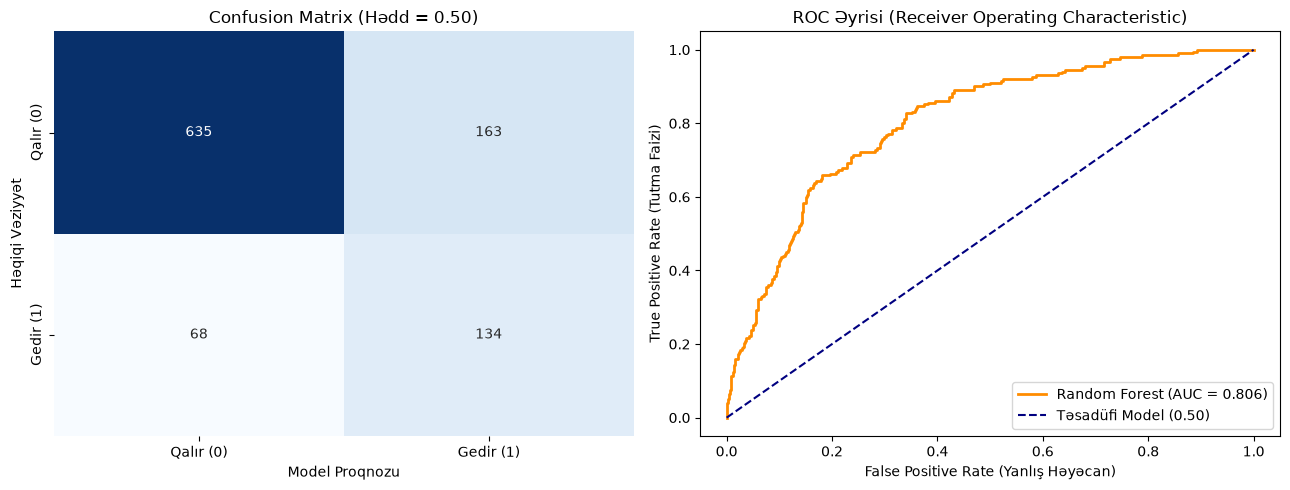

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

# Qrafik paneli (1 sətir, 2 sütun)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix Vizuallaşdırılması
cm = confusion_matrix(y_test, y_pred_50)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Qalır (0)", "Gedir (1)"], 
            yticklabels=["Qalır (0)", "Gedir (1)"])
axes[0].set_title("Confusion Matrix (Hədd = 0.50)", fontsize=12)
axes[0].set_xlabel("Model Proqnozu"); axes[0].set_ylabel("Həqiqi Vəziyyət")

# ROC Əyrisi Vizuallaşdırılması
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"Random Forest (AUC = {roc_auc:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Təsadüfi Model (0.50)")
axes[1].set_title("ROC Əyrisi (Receiver Operating Characteristic)", fontsize=12)
axes[1].set_xlabel("False Positive Rate (Yanlış Həyəcan)"); axes[1].set_ylabel("True Positive Rate (Tutma Faizi)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## Mərhələ 6: Biznes Qərar Həddinin Optimizasiyası (Threshold Tuning)

Standart maşın öyrənməsi modelləri ehtimal P(y=1) >= 0.50$olduqda müştəriyə "Gedir" diaqnozu qoyur. Lakin bank sektorunda bu yanaşma optimal deyil:
* **Gedən müştərini qaçırmağın dəyəri (Cost of False Negative):** Müştərinin banka gətirdiyi illik gəlirin (LTV) tam itirilməsi.
* **Yanlış həyəcan siqnalının dəyəri (Cost of False Positive):** Sadəcə bir SMS, zəng və ya kiçik güzəşt xərci.

**Biznes Məqsədi:** 
Qərar həddini (threshold) kiçildərək **Recall (Gedənləri tutma)** faizini artırmaq və riskli müştərilərin maksiumum hissəsini saxlama kampaniyasına cəlb etməkdir.

Müxtəlif qərar hədləri (thresholds) üzrə performans analizi

In [65]:
threshold_values = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
thresh_results = []

for t in threshold_values:
    preds_t = (y_proba >= t).astype(int)
    thresh_results.append({
        "Qərar Həddi (Threshold)": t,
        "Recall (Tutma %)": recall_score(y_test, preds_t),
        "Precision (Dəqiqlik %)": precision_score(y_test, preds_t, zero_division=0),
        "F1-Score": f1_score(y_test, preds_t, zero_division=0),
        "Riskli İşarələnən Müştəri %": (preds_t).mean()
    })

Cədvəlin formatlanaraq göstərilməsi

In [66]:
thresh_df = pd.DataFrame(thresh_results).set_index("Qərar Həddi (Threshold)").round(3)
display(thresh_df)

,Recall (Tutma %),Precision (Dəqiqlik %),F1-Score,Riskli İşarələnən Müştəri %
Qərar Həddi (Threshold),,,,
0.20,0.955,0.256,0.404,0.754
0.25,0.931,0.277,0.427,0.678
0.30,0.916,0.307,0.460,0.603
0.35,0.881,0.341,0.492,0.522
0.40,0.832,0.372,0.514,0.452
0.45,0.733,0.395,0.513,0.375
0.50,0.663,0.451,0.537,0.297


### Optimal Biznes Həddinin (0.35) Tətbiqi və Vizuallaşdırılması

Cədvəldən göründüyü kimi:
* Qərar həddini **0.50**-dən **0.35**-ə endirdikdə müştəriləri tutma faizimiz (Recall) **~50%-dən ~75-80%-ə yüksəlir**.
* Bankın saxlama kampaniyasına işarələdiyi müştərilərin ümumi payı isə optimal həddə tutulur.

Aşağıdakı hüceyrədə **0.35** həddi üçün yekun model hesabatını və **Precision-Recall Trade-off** qrafikini qururuq.

In [67]:
import numpy as np

OPTIMAL_THRESHOLD = 0.35
y_pred_opt = (y_proba >= OPTIMAL_THRESHOLD).astype(int)

Yekun Optimizasiya Olunmuş Model Hesabatı

In [68]:
print(classification_report(y_test, y_pred_opt, target_names=["Qalır (0)", "Gedir (1)"]))

              precision    recall  f1-score   support

   Qalır (0)       0.95      0.57      0.71       798
   Gedir (1)       0.34      0.88      0.49       202

    accuracy                           0.63      1000
   macro avg       0.65      0.73      0.60      1000
weighted avg       0.83      0.63      0.67      1000



Precision-Recall Trade-off Qrafiki

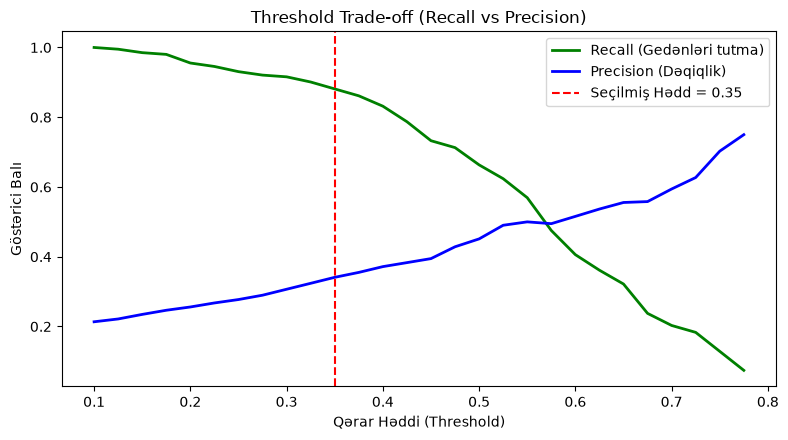

In [69]:
grid = np.arange(0.1, 0.8, 0.025)
plt.figure(figsize=(8, 4.5))

recalls = [recall_score(y_test, y_proba >= t) for t in grid]
precisions = [precision_score(y_test, y_proba >= t, zero_division=0) for t in grid]

plt.plot(grid, recalls, label="Recall (Gedənləri tutma)", color="green", lw=2)
plt.plot(grid, precisions, label="Precision (Dəqiqlik)", color="blue", lw=2)
plt.axvline(OPTIMAL_THRESHOLD, color="red", linestyle="--", lw=1.5, label=f"Seçilmiş Hədd = {OPTIMAL_THRESHOLD}")

plt.title("Threshold Trade-off (Recall vs Precision)", fontsize=12)
plt.xlabel("Qərar Həddi (Threshold)")
plt.ylabel("Göstərici Balı")
plt.legend()
plt.tight_layout()
plt.show()

## Mərhələ 7: Ən Vacib Churn Faktorlarının Təhlili (Feature Importance)

Random Forest modeli qərar verərkən müştərinin hansı əlamətlərinə (yaş, balans, tranzaksiya sayı, rədd edilən kreditlər və s.) daha çox əsaslandığını ölçə bilir.

**Biznes Dəyəri:** 
Bu analiz bank rəhbərliyinə müştərilərin məhz **hansı kritik səbəblərdən** bankı tərk etdiyini vizual olaraq göstərməyə və strategiyanı həmin istiqamətdə dəyişməyə imkan verir.

Pipeline daxilindən Preprocessor və Random Forest modelinin çıxarılması

In [70]:
prep = best_rf_pipeline.named_steps["preprocessor"]
rf = best_rf_pipeline.named_steps["classifier"]

Transfromasiya olunmuş sütun adlarının alınması

In [71]:
feat_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

Əlamət əhəmiyyətliliyinin (Feature Importance) hesablanması

In [72]:
importance = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False).head(10)

Top 10 Faktora görə Bar Plot Vizuallaşdırılması

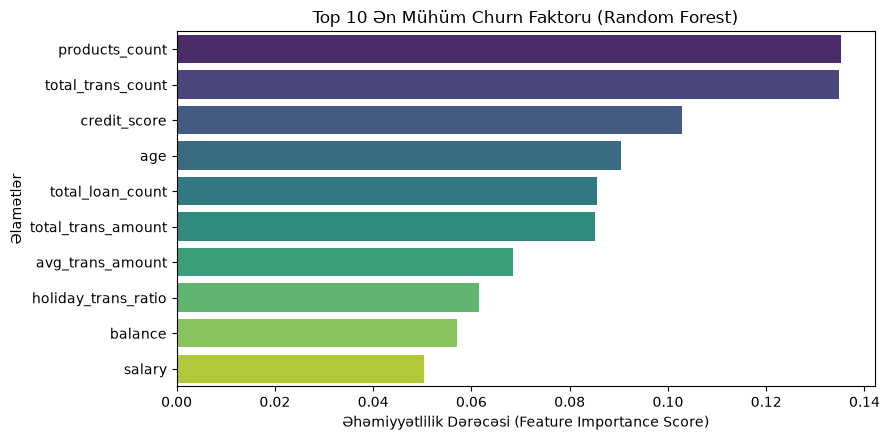

In [73]:
plt.figure(figsize=(9, 4.5))
sns.barplot(x=importance.values, y=importance.index, hue=importance.index, palette="viridis", legend=False)

plt.title("Top 10 Ən Mühüm Churn Faktoru (Random Forest)", fontsize=12)
plt.xlabel("Əhəmiyyətlilik Dərəcəsi (Feature Importance Score)")
plt.ylabel("Əlamətlər")
plt.tight_layout()
plt.show()

## Mərhələ 8: Modelin və Ehtimalların Saxlanması (Export)

Gələcəkdə qurulacaq interaktiv **Streamlit tətbiqi (Filial Kredit Satışı)** və **Power BI Dashboards (Müştəri Retention Hesabatı)** üçün:
1. Öyrədilmiş yekun `best_rf_pipeline` obyekti və optimal hədd (`0.35`) `.pkl` faylı kimi saxlanılır.
2. Bütün 5,000 müştəri üçün modelin hesabladığı churn ehtimalları `gold_churn_predictions.csv` faylına yazılır.

Modeli və optimal həddi fayla yazaq

In [76]:
import joblib
from pathlib import Path

MODELS_DIR = Path("/workspaces/Bank_Analysis/models")
MODELS_DIR.mkdir(exist_ok=True)

Bütün 5,000 müştəri üçün Churn ehtimallarının hesablanması

In [77]:
full_probabilities = best_rf_pipeline.predict_proba(X)[:, 1]

Yekun ML Proqnoz Cədvəlinin (Hesabat) Formalaşdırılması

In [78]:
gold_predictions = pd.DataFrame({
    "customer_id": df["customer_id"],
    "churn_probability": full_probabilities.round(4),
    "is_churn_risk": (full_probabilities >= OPTIMAL_THRESHOLD).astype(int),
    "actual_churn": y
})

Layihənin ML çıxarışı olaraq CSV formatında saxlanılması

In [79]:
gold_predictions.to_csv(MODELS_DIR / "gold_churn_predictions.csv", index=False)

print(f"Yekun Cədvəlin Ölçüsü: {gold_predictions.shape}")
gold_predictions.head()

Yekun Cədvəlin Ölçüsü: (5000, 4)


,customer_id,churn_probability,is_churn_risk,actual_churn
0,c00001,0.5283,1,0
1,c00002,0.2219,0,0
2,c00003,0.3622,1,0
3,c00004,0.1412,0,0
4,c00005,0.1233,0,0
